Instructions: before running, add your email address in Section 2 (Parameters) for access to the PubMed API

### 📦 1 | Install & Import Required Packages
---

**1.1 | Install Required Packages**

In [ ]:
!pip install biopython >/dev/null
!pip install plotnine >/dev/null

**1.2 | Import Required Packages**

In [ ]:
from    Bio import Entrez
import  pandas as pd
from    datetime import datetime
import  matplotlib.pyplot as plt
from    plotnine import *
from    mizani.formatters import comma_format
import  time

### 🔧 2 | Parameters
---

In [ ]:
# Set email for PubMed API
Entrez.email = "your.email@example.org"  # Replace with a contact email before running

# Define the start and end years for the PubMed API search
start_year = 1980
end_year = 2024

# Define the search terms for the PubMed API
search_terms = {
    "Oxford (1991)": (
        '("ME/CFS" OR "Myalgic Encephalomyelitis" OR "Chronic Fatigue Syndrome" OR "CFS/ME" OR "Systemic Exertion Intolerance Disease") '
        'AND ("Oxford criteria" OR "Sharpe 1991")'
    ),
    "Fukuda (1994)": (
        '("ME/CFS" OR "Myalgic Encephalomyelitis" OR "Chronic Fatigue Syndrome" OR "CFS/ME" OR "Systemic Exertion Intolerance Disease") '
        'AND ("Fukuda criteria" OR "CDC 1994" OR "Fukuda et al")'
    ),
    "CCC (2003)": (
        '("ME/CFS" OR "Myalgic Encephalomyelitis" OR "Chronic Fatigue Syndrome" OR "CFS/ME" OR "Systemic Exertion Intolerance Disease") '
        'AND ("Canadian Consensus Criteria" OR "CCC 2003" OR "Carruthers et al")'
    ),
     "ICC (2011)": (
        '("ME/CFS" OR "Myalgic Encephalomyelitis" OR "Chronic Fatigue Syndrome" OR "CFS/ME" OR "Systemic Exertion Intolerance Disease") '
        'AND ("International Consensus Criteria" OR "ICC 2011" OR "Carruthers 2011")'
    ),
    "IOM (2015)": (
        '("ME/CFS" OR "Myalgic Encephalomyelitis" OR "Chronic Fatigue Syndrome" OR "CFS/ME" OR "Systemic Exertion Intolerance Disease") '
        'AND ("Institute of Medicine" OR "IOM 2015" OR "SEID")'
    )
}

# Define ME/CFS diagnostic criteria colours
criteria_colors = {
    "Oxford (1991)": "#FFC2E6",
    "Fukuda (1994)": "#E57399",
    "CCC (2003)": "#FFD8A8",
    "ICC (2011)": "#B6FDFF",
    "IOM (2015)": "#7BB3F3"
}

# Define grouped criteria colours
grouped_criteria_colors = {
    "Legacy - PEM Not Required (Oxford, Fukuda)": "#E57399",
    "Modern - PEM Required (CCC, ICC, IOM)": "#B4D9B5"
}

# Define moving average window
smoothing_window = 3

### 🚰  3 | Data Import - from PubMed API
---

In [ ]:
# Define a function for fetching data from PubMed
def fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year):
    """
    Fetches publication counts from PubMed for multiple search terms over a range of years.

    :param search_terms: Dictionary of search terms (diseases) and their PubMed query strings.
                        IMPORTANT: Multi-word phrases should be surrounded by quotes
                        if you want them treated as an exact phrase.
    :param start_year: Start year for the data collection.
    :param end_year: End year for the data collection.
    :return: DataFrame with years as rows and diseases as columns, containing publication counts.
    """

    publication_counts = {term: [] for term in search_terms}
    years = range(start_year, end_year + 1)

    for year in years:
        for disease_label, query in search_terms.items():
            # Construct the query with [dp] (date of publication)
            full_query = f"{query} AND ({year}[dp])"

            handle = Entrez.esearch(db="pubmed", term=full_query, retmax=100000)
            record = Entrez.read(handle)
            count = int(record["Count"])
            publication_counts[disease_label].append(count)
            handle.close()

            # Optional: small sleep to respect NCBI rate limits (~3 requests/sec)
            #time.sleep(0.34)

    # Create a DataFrame from the collected 🛠️data
    df = pd.DataFrame(publication_counts, index=years)
    df.index.name = 'Year'
    return df

# Fetching the data (to be executed in an environment where Biopython is installed)
publications_df = fetch_pubmed_data_for_multiple_terms(search_terms, start_year, end_year)

# Check result
publications_df.tail()

,Oxford (1991),Fukuda (1994),CCC (2003),ICC (2011),IOM (2015)
Year,,,,,
2020,0,8,5,5,9
2021,0,5,3,6,6
2022,1,3,3,6,3
2023,0,6,7,5,5
2024,1,3,7,4,6


### 🛠️ 4 | Data Wrangling
---

In [ ]:
# Transforming the DataFrame to long format
df_long = publications_df.reset_index().melt(id_vars='Year', var_name='Diagnostic Criteria', value_name='Publications')

# Check result
df_long.tail(5)

,Year,Diagnostic Criteria,Publications
220,2020,IOM (2015),9
221,2021,IOM (2015),6
222,2022,IOM (2015),3
223,2023,IOM (2015),5
224,2024,IOM (2015),6


In [ ]:
# Create copied dataframe
df_long_grouped = df_long.copy()

# Allocate diagnostic criteria into 'Legacy' and 'Modern'
df_long_grouped['Diagnostic Criteria'] = df_long_grouped['Diagnostic Criteria'].apply(
    lambda x: 'Legacy - PEM Not Required (Oxford, Fukuda)' if x in ['Oxford (1991)', 'Fukuda (1994)'] else 'Modern - PEM Required (CCC, ICC, IOM)'
)

# Calculate number of each grouped criteria
df_long_grouped = df_long_grouped.groupby(['Year', 'Diagnostic Criteria']).sum().reset_index()

# Check result
df_long_grouped.tail(5)

,Year,Diagnostic Criteria,Publications
85,2022,"Modern - PEM Required (CCC, ICC, IOM)",12
86,2023,"Legacy - PEM Not Required (Oxford, Fukuda)",6
87,2023,"Modern - PEM Required (CCC, ICC, IOM)",17
88,2024,"Legacy - PEM Not Required (Oxford, Fukuda)",4
89,2024,"Modern - PEM Required (CCC, ICC, IOM)",17


In [ ]:
# Create copied dataframe
df_smoothed = df_long_grouped.copy()

# Perform smoothing with moving average
df_smoothed['Smoothed'] = (
    df_smoothed
    .groupby('Diagnostic Criteria')['Publications']
    .transform(lambda x: x.rolling(window=smoothing_window, center=True).mean())
)

# Check results
df_smoothed.tail(20)

,Year,Diagnostic Criteria,Publications,Smoothed
70,2015,"Legacy - PEM Not Required (Oxford, Fukuda)",18,11.000000
71,2015,"Modern - PEM Required (CCC, ICC, IOM)",17,10.333333
72,2016,"Legacy - PEM Not Required (Oxford, Fukuda)",9,10.666667
73,2016,"Modern - PEM Required (CCC, ICC, IOM)",9,12.333333
74,2017,"Legacy - PEM Not Required (Oxford, Fukuda)",5,6.333333
75,2017,"Modern - PEM Required (CCC, ICC, IOM)",11,9.000000
76,2018,"Legacy - PEM Not Required (Oxford, Fukuda)",5,7.000000
77,2018,"Modern - PEM Required (CCC, ICC, IOM)",7,10.666667
78,2019,"Legacy - PEM Not Required (Oxford, Fukuda)",11,8.000000
79,2019,"Modern - PEM Required (CCC, ICC, IOM)",14,13.333333


### 📈  5 | Visualise Results
---

/usr/local/lib/python3.11/dist-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 5 rows containing missing values.


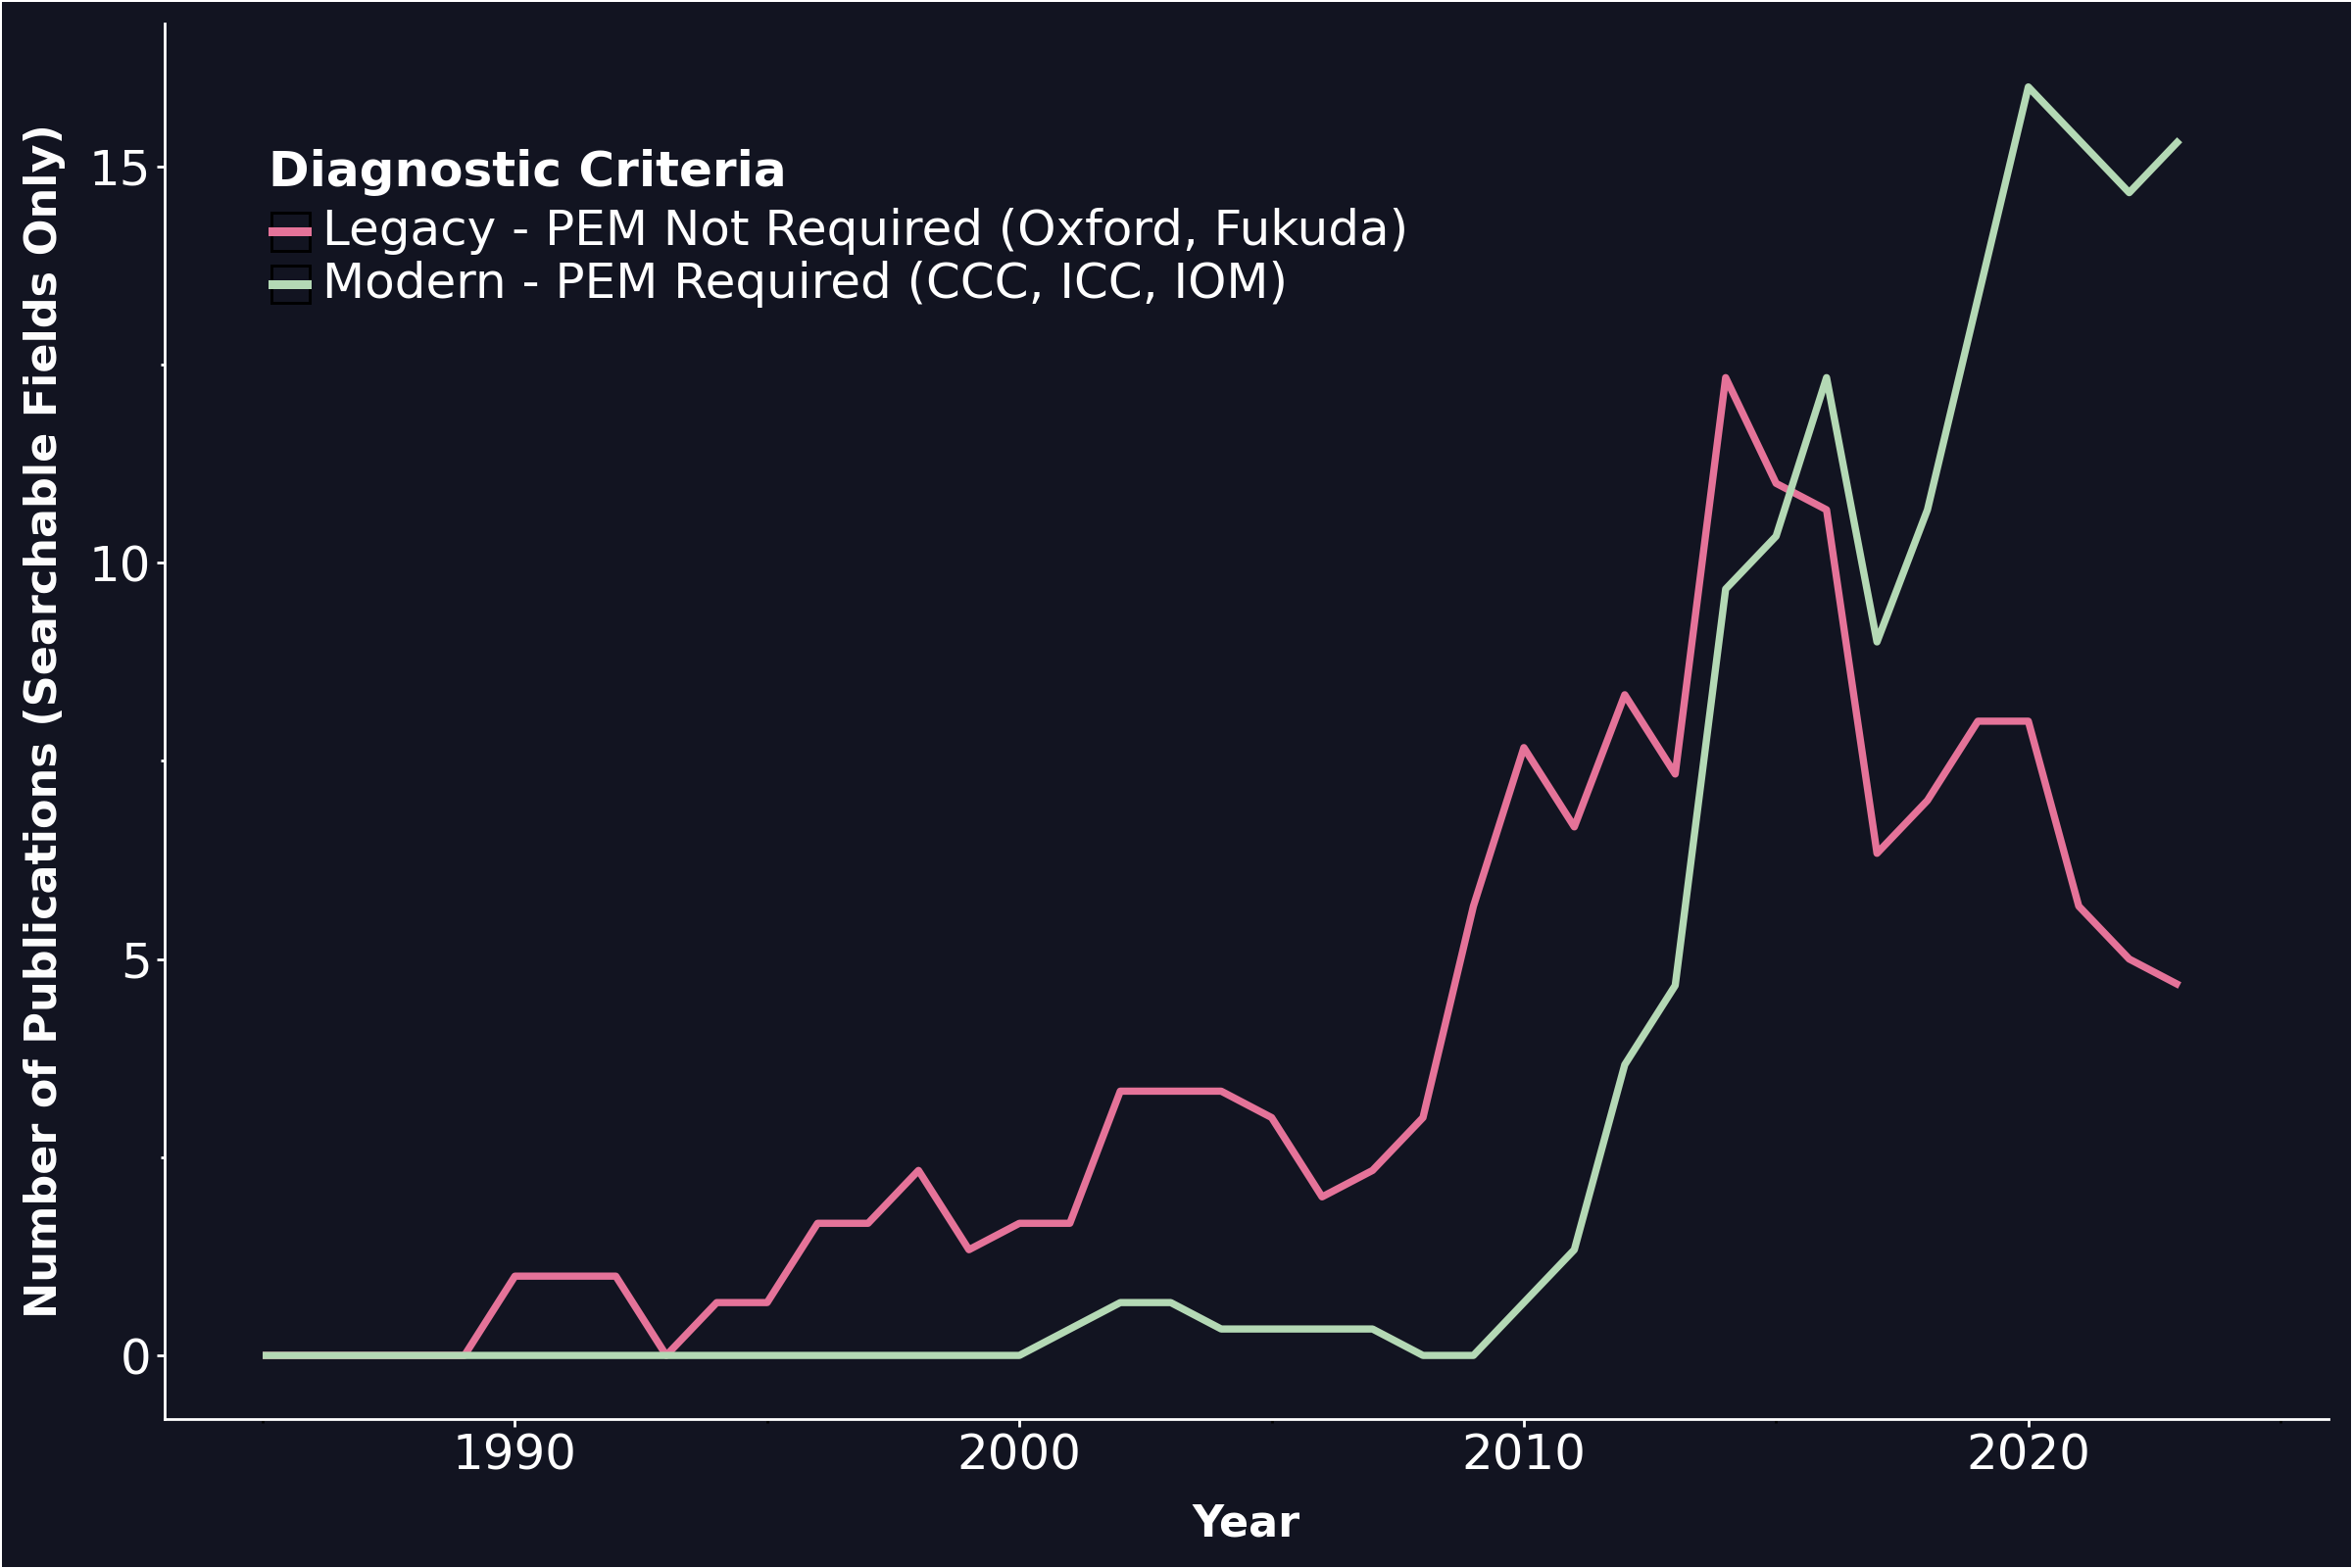

In [ ]:
# Update the plot with pastel colors
plot = (ggplot(df_smoothed, aes(x='Year', y='Smoothed', color='Diagnostic Criteria')) +
        geom_line(size=1.5) +
        labs(y='Number of Publications (Searchable Fields Only)') +
        theme_classic() +
        theme(
            figure_size=(12, 8),
            axis_title=element_text(size=16, weight='bold', color='white'),
            axis_text=element_text(size=18, color='white'),
            #plot_title=element_text(size=16, weight='bold', color='white', hjust=0),
            legend_title=element_text(size=18, weight='bold', color='white'),
            legend_text=element_text(size=18, color='white'),
            plot_background=element_rect(fill='#121421', color=None),
            panel_background=element_rect(fill='#121421', color=None),
            legend_background=element_rect(fill='#121421', color=None),
            legend_key=element_rect(fill='#121421', color=None),
            legend_position=(0.1, 0.90),
            axis_line=element_line(color='white', size=1),
            axis_ticks=element_line(color='white', size=1)
        ) +
        scale_y_continuous(labels=comma_format()) +
        scale_x_continuous(limits=[1985, 2024]) +
        scale_color_manual(values=grouped_criteria_colors)
       )

# Display the plot
plot